In [1]:
# ================================
# 0. INSTALL REQUIRED LIBRARIES 
# ================================
# Uses the *notebook kernel* Python (not system pyenv). Prefer running the IMPORT cell below instead.
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "nibabel", "matplotlib", "scikit-image", "scikit-learn", "tqdm",
])
print("Installed into:", sys.executable)
# RTX Blackwell / sm_120 (RTX 50-series): CUDA 12.8 wheels recommended
# subprocess.check_call([sys.executable, "-m", "pip", "install", "torch", "torchvision", "torchaudio",
#     "--index-url", "https://download.pytorch.org/whl/cu128"])


Installed into: c:\Users\Osama\.pyenv\pyenv-win\versions\3.12.9\python.exe


In [2]:
# Optional: run cell 0 above, or the IMPORT LIBRARIES cell (installs into kernel automatically).
import sys
print("Kernel Python:", sys.executable)

Kernel Python: c:\Users\Osama\.pyenv\pyenv-win\versions\3.12.9\python.exe


In [3]:
# ================================
# IMPORT LIBRARIES
# ================================
import importlib.util
import subprocess
import sys

# Install into *this* kernel's Python if torch is missing (fixes wrong-kernel / fresh env).
if importlib.util.find_spec("torch") is None:
    _pip_line = (
        "install torch torchvision torchaudio "
        "--index-url https://download.pytorch.org/whl/cu128"
    )
    print(
        "PyTorch (cu128) not found — installing for this interpreter.\n"
        "The torch wheel is ~2.7 GB; first install can take 15–60+ minutes. Do not interrupt.\n"
        f'If this fails, run in PowerShell: "{sys.executable}" -m pip {_pip_line}\n'
    )
    try:
        _ipy = get_ipython()
    except NameError:
        _ipy = None
    if _ipy is not None:
        # Prefer %pip so Jupyter shows live pip output (subprocess often fails or times out here).
        _ipy.run_line_magic("pip", _pip_line)
    else:
        _r = subprocess.run(
            [sys.executable, "-m", "pip"] + _pip_line.split(),
            check=False,
        )
        if _r.returncode != 0:
            raise RuntimeError(
                f"pip exited with {_r.returncode}. Retry in a terminal with --no-cache-dir if the download was interrupted."
            )
    importlib.invalidate_caches()
    if importlib.util.find_spec("torch") is None:
        raise RuntimeError(
            "torch still not importable after install. Restart the kernel and run this cell again."
        )

def _ensure_packages(pip_names):
    """Install into *this* Jupyter kernel's Python (not a different env)."""
    missing = [p for p in pip_names if importlib.util.find_spec(p) is None]
    if not missing:
        return
    print("Installing into kernel Python:", sys.executable)
    print("Packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    importlib.invalidate_caches()


_ensure_packages(["numpy", "matplotlib", "nibabel", "scikit-learn"])

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import os
import random

print("Python:", sys.executable)
print("matplotlib OK:", importlib.util.find_spec("matplotlib") is not None)

Installing into kernel Python: c:\Users\Osama\.pyenv\pyenv-win\versions\3.12.9\python.exe
Packages: scikit-learn
Python: c:\Users\Osama\.pyenv\pyenv-win\versions\3.12.9\python.exe
matplotlib OK: True


In [4]:
# ================================
# SET DEVICE (GPU / CPU)
# ================================

import torch

def pick_device():
    if not torch.cuda.is_available():
        return torch.device("cpu")
    try:
        torch.nn.functional.conv2d(
            torch.zeros(1, 4, 8, 8, device="cuda"),
            torch.zeros(8, 4, 3, 3, device="cuda"),
            padding=1,
        )
        torch.backends.cudnn.benchmark = True
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        return torch.device("cuda")
    except RuntimeError:
        print(
            "CUDA kernels failed on this GPU. Install a matching GPU build, e.g.:\n",
            "  pip install torch torchvision --index-url",
            "  https://download.pytorch.org/whl/cu124",
            "\nUsing CPU.",
        )
        return torch.device("cpu")

device = pick_device()

print("Using device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: NVIDIA GeForce RTX 5070


In [5]:
# ================================
# 2. GPU CHECK 
# ================================

import torch

print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version (torch):", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Device count:", torch.cuda.device_count())

Torch version: 2.11.0+cu128
CUDA available: True
CUDA version (torch): 12.8
GPU: NVIDIA GeForce RTX 5070
Device count: 1


In [7]:
# ================================
# DATA PATH (local GPU / Kaggle unzip)
# ================================
# If this fails: download https://www.kaggle.com/datasets/awsaf49/brats20-dataset-training-validation
# then unzip so one of the candidate folders below exists, OR set env BRATS2020_TRAINING_DIR
# to the folder that contains BraTS20_Training_xxx patient folders.

from pathlib import Path
import os

def resolve_brats2020_training_dir():
    env = os.environ.get("BRATS2020_TRAINING_DIR", "").strip()
    if env:
        p = Path(env)
        if p.is_dir():
            return str(p.resolve())

    root = Path.cwd().resolve()
    candidates = [
        root / "data" / "BraTS2020_TrainingData" / "MICCAI_BraTS2020_TrainingData",
        root / "data" / "MICCAI_BraTS2020_TrainingData",
        root / "BraTS2020_TrainingData" / "MICCAI_BraTS2020_TrainingData",
        root / "MICCAI_BraTS2020_TrainingData",
        root / "brats20-dataset-training-validation" / "MICCAI_BraTS2020_TrainingData",
        root / "brats20-dataset-training-validation" / "BraTS2020_TrainingData" / "MICCAI_BraTS2020_TrainingData",
    ]
    for c in candidates:
        if c.is_dir():
            return str(c.resolve())

    msg = "Could not find MICCAI_BraTS2020_TrainingData. Tried:\n" + "\n".join(str(x) for x in candidates)
    raise FileNotFoundError(msg)


train_path = resolve_brats2020_training_dir()
patients = sorted(
    p
    for p in os.listdir(train_path)
    if os.path.isdir(os.path.join(train_path, p)) and p.startswith("BraTS")
)
print("Training data:", train_path)
print("Patients:", len(patients))

Training data: D:\MSAI\Semester 2\Deep Learning\Project\Project\AI600-DeepLearning2502-SemesterProject\data\BraTS2020_TrainingData\MICCAI_BraTS2020_TrainingData
Patients: 369


In [8]:
# ================================
# SELECT PATIENT
# ================================

patient = patients[0]
patient_path = os.path.join(train_path, patient)

print("Patient:", patient)

Patient: BraTS20_Training_001


In [9]:
# ================================
# LOAD ONE MRI 
# ================================

files = os.listdir(patient_path)

t1 = nib.load(os.path.join(patient_path, [f for f in files if "t1.nii" in f.lower()][0])).get_fdata()

print("Shape:", t1.shape)

Shape: (240, 240, 155)


In [10]:
# ================================
# LOAD MRI DATA 
# ================================

files = os.listdir(patient_path)

t1 = nib.load(os.path.join(patient_path, [f for f in files if "t1.nii" in f.lower()][0])).get_fdata()
t1ce = nib.load(os.path.join(patient_path, [f for f in files if "t1ce" in f.lower()][0])).get_fdata()
t2 = nib.load(os.path.join(patient_path, [f for f in files if "t2.nii" in f.lower()][0])).get_fdata()
flair = nib.load(os.path.join(patient_path, [f for f in files if "flair" in f.lower()][0])).get_fdata()

seg = nib.load(os.path.join(patient_path, [f for f in files if "seg" in f.lower()][0])).get_fdata()

In [11]:
# ================================
# STACK MRI MODALITIES
# ================================

image = np.stack([t1, t1ce, t2, flair], axis=0)

print("Image shape:", image.shape)

Image shape: (4, 240, 240, 155)


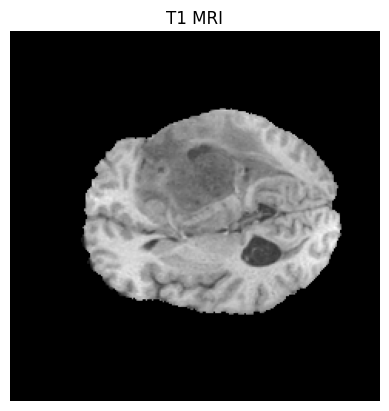

In [12]:
# ================================
# VISUALIZE ONE SLICE
# ================================

plt.imshow(t1[:, :, 70], cmap='gray')
plt.title("T1 MRI")
plt.axis('off')
plt.show()

In [13]:
# ================================
# CREATE 2D SLICES
# ================================

def create_slices(image, mask):
    slices = []
    
    for i in range(image.shape[-1]):
        
        img_slice = image[:, :, :, i]   # (4, H, W)
        mask_slice = mask[:, :, i]      # (H, W)
        
        # Skip slices without tumor
        if np.sum(mask_slice) == 0:
            continue
        
        slices.append((img_slice, mask_slice))
    
    return slices

In [14]:
# ================================
# GENERATE SLICES
# ================================

slices = create_slices(image, seg)

print("Total useful slices:", len(slices))

Total useful slices: 83


In [15]:
# ================================
# IMPORT TORCH
# ================================

import torch
from torch.utils.data import Dataset, DataLoader

In [16]:
# ================================
# CUSTOM DATASET CLASS
# ================================

class BrainTumorDataset(Dataset):
    def __init__(self, slices):
        self.slices = slices

    def __len__(self):
        return len(self.slices)

    def __getitem__(self, idx):
        image, mask = self.slices[idx]
        
        # Convert to float32
        image = image.astype(np.float32)
        mask = mask.astype(np.float32)
        mask = (mask > 0).astype(np.float32)
        
        # Convert to PyTorch tensors
        image = torch.tensor(image)
        mask = torch.tensor(mask)
        
        mask = mask.unsqueeze(0)   # shape: (1, H, W)
        
        return image, mask

In [17]:
# ================================
# CREATE DATASET
# ================================

dataset = BrainTumorDataset(slices)

print("Dataset size:", len(dataset))

Dataset size: 83


In [18]:
# ================================
# CREATE DATALOADER
# ================================

dataloader = DataLoader(dataset, batch_size=4, shuffle=True)

# Get one batch
images, masks = next(iter(dataloader))

print("Batch image shape:", images.shape)
print("Batch mask shape:", masks.shape)

Batch image shape: torch.Size([4, 4, 240, 240])
Batch mask shape: torch.Size([4, 1, 240, 240])


In [19]:
# ================================
# DOUBLE CONVOLUTION BLOCK
# ================================

import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )
    
    def forward(self, x):
        return self.conv(x)

In [20]:
# ================================
# U-NET MODEL
# ================================

class UNet(nn.Module):
    def __init__(self):
        super(UNet, self).__init__()
        
        # Encoder
        self.down1 = DoubleConv(4, 64)
        self.pool1 = nn.MaxPool2d(2)
        
        self.down2 = DoubleConv(64, 128)
        self.pool2 = nn.MaxPool2d(2)
        
        self.down3 = DoubleConv(128, 256)
        self.pool3 = nn.MaxPool2d(2)
        
        # Bottleneck
        self.bottleneck = DoubleConv(256, 512)
        
        # Decoder
        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv1 = DoubleConv(512, 256)
        
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv2 = DoubleConv(256, 128)
        
        self.up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv3 = DoubleConv(128, 64)
        
        # Output
        self.out = nn.Conv2d(64, 1, kernel_size=1)
    
    def forward(self, x):
        # Encoder
        d1 = self.down1(x)
        p1 = self.pool1(d1)
        
        d2 = self.down2(p1)
        p2 = self.pool2(d2)
        
        d3 = self.down3(p2)
        p3 = self.pool3(d3)
        
        # Bottleneck
        b = self.bottleneck(p3)
        
        # Decoder
        u1 = self.up1(b)
        u1 = torch.cat([u1, d3], dim=1)
        u1 = self.conv1(u1)
        
        u2 = self.up2(u1)
        u2 = torch.cat([u2, d2], dim=1)
        u2 = self.conv2(u2)
        
        u3 = self.up3(u2)
        u3 = torch.cat([u3, d1], dim=1)
        u3 = self.conv3(u3)
        
        return self.out(u3)

In [21]:
# ================================
# INITIALIZE MODEL
# ================================

# device: set in "SET DEVICE (GPU / CPU)" cell above

model = UNet().to(device)

print("Model loaded on:", device)

Model loaded on: cuda


In [22]:
# ================================
# TEST MODEL OUTPUT
# ================================

images, masks = next(iter(dataloader))

images = images.to(device)

outputs = model(images)

print("Output shape:", outputs.shape)

Output shape: torch.Size([4, 1, 240, 240])


In [23]:
# ================================
# DICE LOSS FUNCTION
# ================================

class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super(DiceLoss, self).__init__()
        self.smooth = smooth

    def forward(self, preds, targets):
        preds = torch.sigmoid(preds)
        
        preds = preds.contiguous().view(-1)
        targets = targets.contiguous().view(-1)
        
        intersection = (preds * targets).sum()
        
        dice = (2. * intersection + self.smooth) / (
            preds.sum() + targets.sum() + self.smooth
        )
        
        # 🔥 CLAMP to avoid negative loss
        dice = torch.clamp(dice, 0, 1)
        
        return 1 - dice

In [24]:
# ================================
# LOSS + OPTIMIZER
# ================================

criterion = DiceLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [25]:
# ================================
# TRAINING LOOP
# ================================

num_epochs = 10

model.train()

for epoch in range(num_epochs):
    epoch_loss = 0
    
    for images, masks in dataloader:
        
        images = images.to(device)
        masks = masks.to(device)
        
        # Forward
        outputs = model(images)
        loss = criterion(outputs, masks)
        
        # Backward
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
    
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss/len(dataloader):.4f}")

Epoch [1/10], Loss: 0.8608
Epoch [2/10], Loss: 0.9226
Epoch [3/10], Loss: 1.0000
Epoch [4/10], Loss: 1.0000
Epoch [5/10], Loss: 1.0000
Epoch [6/10], Loss: 1.0000
Epoch [7/10], Loss: 1.0000
Epoch [8/10], Loss: 1.0000
Epoch [9/10], Loss: 1.0000
Epoch [10/10], Loss: 1.0000


In [26]:
# ================================
# GET PREDICTIONS
# ================================

model.eval()

with torch.no_grad():
    images, masks = next(iter(dataloader))
    images = images.to(device)

    outputs = model(images)
    outputs = torch.sigmoid(outputs)

    images = images.cpu()
    masks = masks.cpu()
    outputs = outputs.cpu()

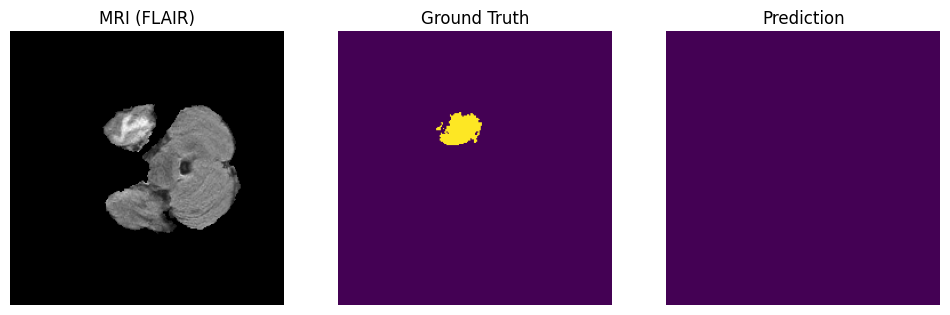

In [27]:
# ================================
# SHOW RESULTS
# ================================

import matplotlib.pyplot as plt

idx = 0  # change 0,1,2,3 to see different ones

plt.figure(figsize=(12,4))

# MRI
plt.subplot(1,3,1)
plt.imshow(images[idx][3], cmap='gray')
plt.title("MRI (FLAIR)")
plt.axis('off')

# Ground truth
plt.subplot(1,3,2)
plt.imshow(masks[idx][0])
plt.title("Ground Truth")
plt.axis('off')

# Prediction
plt.subplot(1,3,3)
plt.imshow(outputs[idx][0] > 0.5)
plt.title("Prediction")
plt.axis('off')

plt.show()

In [28]:
# ================================
# DICE SCORE
# ================================

def dice_score(preds, targets, threshold=0.5):
    preds = (preds > threshold).float()
    
    intersection = (preds * targets).sum()
    union = preds.sum() + targets.sum()
    
    dice = (2 * intersection) / (union + 1e-6)
    return dice.item()

In [29]:
# ================================
# TEST DICE
# ================================

score = dice_score(outputs[0][0], masks[0][0])
print("Dice Score:", score)

Dice Score: 0.0


In [30]:
# ================================
# SAVE MODEL
# ================================

torch.save(model.state_dict(), "unet_brain_tumor.pth")

In [31]:
# ================================
# LOAD MULTIPLE PATIENTS
# ================================

all_slices = []

num_patients = 10   # you can increase later

for patient in patients[:num_patients]:
    
    patient_path = os.path.join(train_path, patient)
    files = os.listdir(patient_path)
    
    t1 = nib.load(os.path.join(patient_path, [f for f in files if "t1.nii" in f.lower()][0])).get_fdata()
    t1ce = nib.load(os.path.join(patient_path, [f for f in files if "t1ce" in f.lower()][0])).get_fdata()
    t2 = nib.load(os.path.join(patient_path, [f for f in files if "t2.nii" in f.lower()][0])).get_fdata()
    flair = nib.load(os.path.join(patient_path, [f for f in files if "flair" in f.lower()][0])).get_fdata()
    seg = nib.load(os.path.join(patient_path, [f for f in files if "seg" in f.lower()][0])).get_fdata()
    
    image = np.stack([t1, t1ce, t2, flair], axis=0)
    
    slices = create_slices(image, seg)
    
    all_slices.extend(slices)

print("Total slices from multiple patients:", len(all_slices))

Total slices from multiple patients: 630


In [32]:
# ================================
# TRAIN / VALIDATION SPLIT
# ================================

from sklearn.model_selection import train_test_split

train_slices, val_slices = train_test_split(all_slices, test_size=0.2, random_state=42)

print("Train slices:", len(train_slices))
print("Validation slices:", len(val_slices))

Train slices: 504
Validation slices: 126


In [33]:
# ================================
# CREATE DATASETS
# ================================

train_dataset = BrainTumorDataset(train_slices)
val_dataset = BrainTumorDataset(val_slices)

In [34]:
# ================================
# CREATE DATALOADERS
# ================================

from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))

Train batches: 126
Val batches: 32


In [35]:
# ================================
# RESET MODEL
# ================================

model = UNet().to(device)

In [36]:
# ================================
# LOSS + OPTIMIZER
# ================================

import torch.nn as nn

bce = nn.BCEWithLogitsLoss()

def combined_loss(preds, targets):
    dice = DiceLoss()(preds, targets)
    bce_loss = bce(preds, targets)
    return dice + bce_loss

criterion = combined_loss
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [37]:
# ================================
# TRAINING WITH VALIDATION
# ================================

num_epochs = 25

for epoch in range(num_epochs):
    # -------- TRAIN --------
    model.train()
    train_loss = 0
    
    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)
        
        outputs = model(images)
        loss = criterion(outputs, masks)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
    
    # -------- VALIDATION --------
    model.eval()
    val_loss = 0
    
    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, masks)
            
            val_loss += loss.item()
    
    print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {train_loss/len(train_loader):.4f} | Val Loss: {val_loss/len(val_loader):.4f}")

Epoch [1/25] | Train Loss: 0.8941 | Val Loss: 0.5433
Epoch [2/25] | Train Loss: 0.5021 | Val Loss: 0.4872


Epoch [3/25] | Train Loss: 0.4369 | Val Loss: 0.4919
Epoch [4/25] | Train Loss: 0.4375 | Val Loss: 0.4073
Epoch [5/25] | Train Loss: 0.3989 | Val Loss: 0.3629
Epoch [6/25] | Train Loss: 0.3759 | Val Loss: 0.3906
Epoch [7/25] | Train Loss: 0.3702 | Val Loss: 0.3636
Epoch [8/25] | Train Loss: 0.3504 | Val Loss: 0.2878
Epoch [9/25] | Train Loss: 0.2678 | Val Loss: 0.2276
Epoch [10/25] | Train Loss: 0.2288 | Val Loss: 0.1977
Epoch [11/25] | Train Loss: 0.2003 | Val Loss: 0.2021
Epoch [12/25] | Train Loss: 0.1902 | Val Loss: 0.1797
Epoch [13/25] | Train Loss: 0.1845 | Val Loss: 0.1690
Epoch [14/25] | Train Loss: 0.1557 | Val Loss: 0.2032
Epoch [15/25] | Train Loss: 0.1596 | Val Loss: 0.1471
Epoch [16/25] | Train Loss: 0.1317 | Val Loss: 0.1306
Epoch [17/25] | Train Loss: 0.1224 | Val Loss: 0.1196
Epoch [18/25] | Train Loss: 0.1221 | Val Loss: 0.1172
Epoch [19/25] | Train Loss: 0.1040 | Val Loss: 0.1086
Epoch [20/25] | Train Loss: 0.0994 | Val Loss: 0.1070
Epoch [21/25] | Train Loss: 0.1000 

In [38]:
# ================================
# VALIDATION DICE SCORE
# ================================

def dice_score(preds, targets, threshold=0.5):
    preds = (preds > threshold).float()
    
    intersection = (preds * targets).sum()
    union = preds.sum() + targets.sum()
    
    return (2 * intersection / (union + 1e-6)).item()

model.eval()

dice_scores = []

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(device)
        masks = masks.to(device)
        
        outputs = torch.sigmoid(model(images))
        
        for i in range(outputs.shape[0]):
            dice = dice_score(outputs[i], masks[i])
            dice_scores.append(dice)

print("Average Dice Score:", sum(dice_scores)/len(dice_scores))

Average Dice Score: 0.8416254650505762


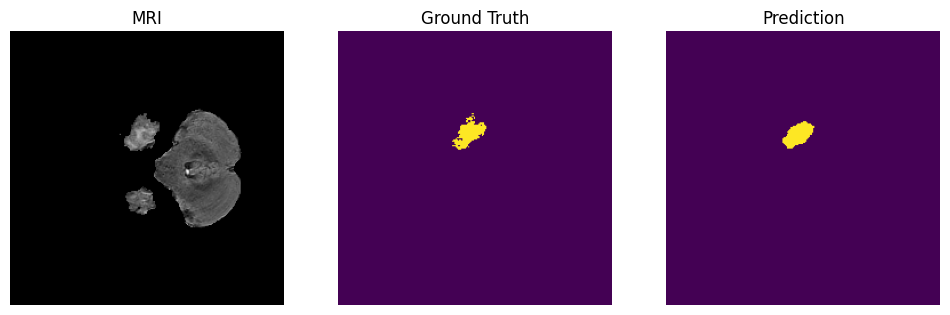

In [39]:
# ================================
# FINAL PREDICTIONS
# ================================

import matplotlib.pyplot as plt

model.eval()

with torch.no_grad():
    images, masks = next(iter(val_loader))
    
    images = images.to(device)
    outputs = torch.sigmoid(model(images))
    
    images = images.cpu()
    masks = masks.cpu()
    outputs = outputs.cpu()

idx = 0

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(images[idx][3], cmap='gray')
plt.title("MRI")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(masks[idx][0])
plt.title("Ground Truth")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(outputs[idx][0] > 0.5)
plt.title("Prediction")
plt.axis('off')

plt.show()

In [40]:
torch.save(model.state_dict(), "unet_baseline.pth")

In [41]:
# ================================
# ATTENTION BLOCK
# ================================

import torch
import torch.nn as nn

class AttentionBlock(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super(AttentionBlock, self).__init__()
        
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1),
            nn.BatchNorm2d(F_int)
        )
        
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1),
            nn.BatchNorm2d(F_int)
        )
        
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        
        return x * psi

In [42]:
# ================================
# ATTENTION U-NET MODEL
# ================================

class AttentionUNet(nn.Module):
    def __init__(self):
        super(AttentionUNet, self).__init__()
        
        # Encoder
        self.down1 = DoubleConv(4, 64)
        self.pool1 = nn.MaxPool2d(2)
        
        self.down2 = DoubleConv(64, 128)
        self.pool2 = nn.MaxPool2d(2)
        
        self.down3 = DoubleConv(128, 256)
        self.pool3 = nn.MaxPool2d(2)
        
        # Bottleneck
        self.bottleneck = DoubleConv(256, 512)
        
        # Attention Gates
        self.att1 = AttentionBlock(256, 256, 128)
        self.att2 = AttentionBlock(128, 128, 64)
        self.att3 = AttentionBlock(64, 64, 32)
        
        # Decoder
        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv1 = DoubleConv(512, 256)
        
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv2 = DoubleConv(256, 128)
        
        self.up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv3 = DoubleConv(128, 64)
        
        # Output
        self.out = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):
        # Encoder
        d1 = self.down1(x)
        p1 = self.pool1(d1)
        
        d2 = self.down2(p1)
        p2 = self.pool2(d2)
        
        d3 = self.down3(p2)
        p3 = self.pool3(d3)
        
        # Bottleneck
        b = self.bottleneck(p3)
        
        # Decoder + Attention
        u1 = self.up1(b)
        d3 = self.att1(g=u1, x=d3)
        u1 = torch.cat([u1, d3], dim=1)
        u1 = self.conv1(u1)
        
        u2 = self.up2(u1)
        d2 = self.att2(g=u2, x=d2)
        u2 = torch.cat([u2, d2], dim=1)
        u2 = self.conv2(u2)
        
        u3 = self.up3(u2)
        d1 = self.att3(g=u3, x=d1)
        u3 = torch.cat([u3, d1], dim=1)
        u3 = self.conv3(u3)
        
        return self.out(u3)

In [43]:
# ================================
# INITIALIZE ATTENTION U-NET
# ================================

model = AttentionUNet().to(device)
print("Attention U-Net loaded!")

Attention U-Net loaded!


In [44]:
# ================================
# RESET OPTIMIZER FOR ATTENTION U-NET
# ================================

optimizer = torch.optim.Adam(model.parameters(), lr=5e-5)

In [45]:
# ================================
# TRAIN ATTENTION U-NET
# ================================

num_epochs = 25

for epoch in range(num_epochs):
    
    # -------- TRAIN --------
    model.train()
    train_loss = 0
    
    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)
        
        outputs = model(images)
        loss = criterion(outputs, masks)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
    
    # -------- VALIDATION --------
    model.eval()
    val_loss = 0
    
    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, masks)
            
            val_loss += loss.item()
    
    print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {train_loss/len(train_loader):.4f} | Val Loss: {val_loss/len(val_loader):.4f}")

Epoch [1/25] | Train Loss: 1.2058 | Val Loss: 0.5839
Epoch [2/25] | Train Loss: 0.3141 | Val Loss: 0.4580
Epoch [3/25] | Train Loss: 0.2529 | Val Loss: 0.2640
Epoch [4/25] | Train Loss: 0.2473 | Val Loss: 0.5485
Epoch [5/25] | Train Loss: 0.2165 | Val Loss: 0.2653
Epoch [6/25] | Train Loss: 0.1943 | Val Loss: 0.2470
Epoch [7/25] | Train Loss: 0.1826 | Val Loss: 0.1999
Epoch [8/25] | Train Loss: 0.2025 | Val Loss: 0.3323
Epoch [9/25] | Train Loss: 0.1864 | Val Loss: 0.2000
Epoch [10/25] | Train Loss: 0.1573 | Val Loss: 0.1858
Epoch [11/25] | Train Loss: 0.1447 | Val Loss: 0.1467
Epoch [12/25] | Train Loss: 0.1487 | Val Loss: 0.1592
Epoch [13/25] | Train Loss: 0.1355 | Val Loss: 0.1897
Epoch [14/25] | Train Loss: 0.1436 | Val Loss: 0.1892
Epoch [15/25] | Train Loss: 0.1241 | Val Loss: 0.1367
Epoch [16/25] | Train Loss: 0.1269 | Val Loss: 0.2064
Epoch [17/25] | Train Loss: 0.1471 | Val Loss: 0.1293
Epoch [18/25] | Train Loss: 0.1236 | Val Loss: 0.1149
Epoch [19/25] | Train Loss: 0.1085 | 

In [46]:
# ================================
# ATTENTION U-NET DICE SCORE
# ================================

model.eval()

dice_scores = []

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(device)
        masks = masks.to(device)
        
        outputs = torch.sigmoid(model(images))
        
        for i in range(outputs.shape[0]):
            dice = dice_score(outputs[i], masks[i])
            dice_scores.append(dice)

print("Attention U-Net Dice:", sum(dice_scores)/len(dice_scores))

Attention U-Net Dice: 0.843269044385543


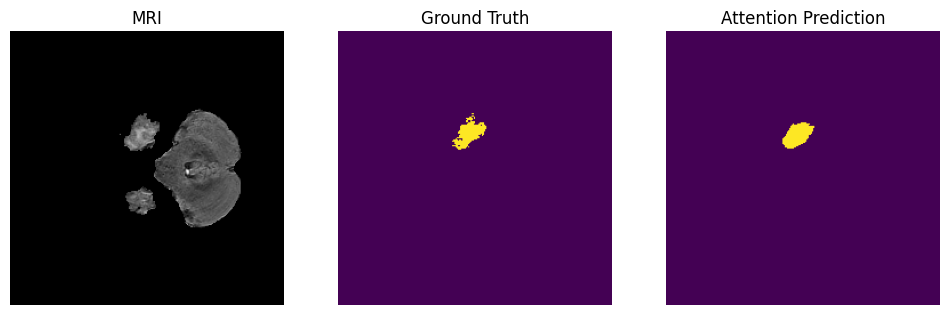

In [47]:
# ================================
# VISUALIZE ATTENTION U-NET RESULTS
# ================================

import matplotlib.pyplot as plt

model.eval()

with torch.no_grad():
    images, masks = next(iter(val_loader))
    
    images = images.to(device)
    outputs = torch.sigmoid(model(images))
    
    images = images.cpu()
    masks = masks.cpu()
    outputs = outputs.cpu()

idx = 0

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(images[idx][3], cmap='gray')
plt.title("MRI")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(masks[idx][0])
plt.title("Ground Truth")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(outputs[idx][0] > 0.5)
plt.title("Attention Prediction")
plt.axis('off')

plt.show()

In [48]:
# ================================
# CREATE 2.5D SLICES
# ================================

def create_slices_25d(image, mask):
    slices = []
    
    for i in range(1, image.shape[-1] - 1):  # avoid edges
        
        # Take 3 consecutive slices
        prev_slice = image[:, :, :, i-1]
        curr_slice = image[:, :, :, i]
        next_slice = image[:, :, :, i+1]
        
        # Stack → (12, H, W)
        img_slice = np.concatenate([prev_slice, curr_slice, next_slice], axis=0)
        
        mask_slice = mask[:, :, i]
        
        # Skip small tumors
        if np.sum(mask_slice) < 50:
            continue
        
        slices.append((img_slice, mask_slice))
    
    return slices

In [49]:
# ================================
# LOAD MULTIPLE PATIENTS 
# ================================

all_slices_25d = []

num_patients = 100

for patient in patients[:num_patients]:
    
    patient_path = os.path.join(train_path, patient)
    files = os.listdir(patient_path)
    
    t1 = nib.load(os.path.join(patient_path, [f for f in files if "t1.nii" in f.lower()][0])).get_fdata()
    t1ce = nib.load(os.path.join(patient_path, [f for f in files if "t1ce" in f.lower()][0])).get_fdata()
    t2 = nib.load(os.path.join(patient_path, [f for f in files if "t2.nii" in f.lower()][0])).get_fdata()
    flair = nib.load(os.path.join(patient_path, [f for f in files if "flair" in f.lower()][0])).get_fdata()
    seg = nib.load(os.path.join(patient_path, [f for f in files if "seg" in f.lower()][0])).get_fdata()
    
    image = np.stack([t1, t1ce, t2, flair], axis=0)
    
    slices = create_slices_25d(image, seg)
    
    all_slices_25d.extend(slices)

print("Total 2.5D slices:", len(all_slices_25d))

Total 2.5D slices: 6141


In [50]:
# ================================
# SPLIT DATA
# ================================

from sklearn.model_selection import train_test_split

train_slices, val_slices = train_test_split(all_slices_25d, test_size=0.2, random_state=42)

print("Train:", len(train_slices))
print("Val:", len(val_slices))

Train: 4912
Val: 1229


In [51]:
# ================================
# DATASET CLASS (2.5D)
# ================================

class BrainTumorDataset(Dataset):
    def __init__(self, slices):
        self.slices = slices

    def __len__(self):
        return len(self.slices)

    def __getitem__(self, idx):
        image, mask = self.slices[idx]
        
        image = image.astype(np.float32)
        mask = mask.astype(np.float32)
        
        # Normalize
        image = (image - image.mean()) / (image.std() + 1e-8)
        
        # Binary mask
        mask = (mask > 0).astype(np.float32)
        
        image = torch.tensor(image)
        mask = torch.tensor(mask).unsqueeze(0)
        
        return image, mask

In [52]:
# ================================
# DATALOADERS (speed: larger batch, workers — set BATCH_SIZE lower if OOM)
# ================================

import sys

train_dataset = BrainTumorDataset(train_slices)
val_dataset = BrainTumorDataset(val_slices)

BATCH_SIZE_25D = 8  # try 16 if VRAM allows; use 4 if out-of-memory
_cuda = torch.cuda.is_available()
_nw = 0 if sys.platform == "win32" else min(8, max(4, (os.cpu_count() or 4) // 2))
_dl_kw = {"batch_size": BATCH_SIZE_25D, "pin_memory": _cuda}
if _nw > 0:
    _dl_kw.update(num_workers=_nw, persistent_workers=True, prefetch_factor=2)

train_loader = DataLoader(train_dataset, shuffle=True, **_dl_kw)
val_loader = DataLoader(val_dataset, shuffle=False, **_dl_kw)
print("2.5D DataLoader batch_size", BATCH_SIZE_25D, "num_workers", _nw)

2.5D DataLoader batch_size 8 num_workers 0


In [53]:
# ================================
# MODEL 2.5D ATTENTION U-NET)
# ================================

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)


class AttentionBlock(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Conv2d(F_g, F_int, 1)
        self.W_x = nn.Conv2d(F_l, F_int, 1)
        self.psi = nn.Conv2d(F_int, 1, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, g, x):
        psi = self.sigmoid(self.psi(torch.relu(self.W_g(g) + self.W_x(x))))
        return x * psi


class AttentionUNet(nn.Module):
    def __init__(self):
        super().__init__()
        
        # 🔥 IMPORTANT CHANGE: 12 CHANNEL INPUT
        self.down1 = DoubleConv(12, 64)
        self.pool1 = nn.MaxPool2d(2)

        self.down2 = DoubleConv(64, 128)
        self.pool2 = nn.MaxPool2d(2)

        self.down3 = DoubleConv(128, 256)
        self.pool3 = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(256, 512)

        self.up1 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.att1 = AttentionBlock(256, 256, 128)
        self.conv1 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.att2 = AttentionBlock(128, 128, 64)
        self.conv2 = DoubleConv(256, 128)

        self.up3 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.att3 = AttentionBlock(64, 64, 32)
        self.conv3 = DoubleConv(128, 64)

        self.out = nn.Conv2d(64, 1, 1)

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(self.pool1(d1))
        d3 = self.down3(self.pool2(d2))

        b = self.bottleneck(self.pool3(d3))

        u1 = self.up1(b)
        d3 = self.att1(u1, d3)
        u1 = self.conv1(torch.cat([u1, d3], dim=1))

        u2 = self.up2(u1)
        d2 = self.att2(u2, d2)
        u2 = self.conv2(torch.cat([u2, d2], dim=1))

        u3 = self.up3(u2)
        d1 = self.att3(u3, d1)
        u3 = self.conv3(torch.cat([u3, d1], dim=1))

        return self.out(u3)

In [54]:
# ================================
# LOSS + OPTIMIZER 
# ================================

bce = nn.BCEWithLogitsLoss()

def combined_loss(preds, targets):
    # Dice uses sigmoid
    preds_sigmoid = torch.sigmoid(preds)
    
    intersection = (preds_sigmoid * targets).sum()
    dice = (2 * intersection) / (preds_sigmoid.sum() + targets.sum() + 1e-6)
    
    # BCE uses RAW logits
    bce_loss = bce(preds, targets)
    
    return (1 - dice) + bce_loss


if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

model = AttentionUNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-5)

from torch.cuda.amp import GradScaler

_use_cuda_amp = device.type == "cuda"
scaler = GradScaler(enabled=_use_cuda_amp)

C:\Users\Osama\AppData\Local\Temp\ipykernel_15348\2652066151.py:29: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=_use_cuda_amp)


In [55]:
# ================================
# TRAINING (mixed precision AMP + async H2D when pin_memory)
# ================================

from torch.cuda.amp import autocast

num_epochs = 25
_nb = device.type == "cuda"

for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0

    for images, masks in train_loader:
        images = images.to(device, non_blocking=_nb)
        masks = masks.to(device, non_blocking=_nb)
        optimizer.zero_grad(set_to_none=True)
        if _use_cuda_amp:
            with autocast():
                outputs = model(images)
                loss = combined_loss(outputs, masks)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = model(images)
            loss = combined_loss(outputs, masks)
            loss.backward()
            optimizer.step()
        train_loss += loss.item()

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device, non_blocking=_nb)
            masks = masks.to(device, non_blocking=_nb)
            if _use_cuda_amp:
                with autocast():
                    outputs = model(images)
                    loss = combined_loss(outputs, masks)
            else:
                outputs = model(images)
                loss = combined_loss(outputs, masks)
            val_loss += loss.item()

    print(f"Epoch {epoch+1}: Train={train_loss/len(train_loader):.4f}, Val={val_loss/len(val_loader):.4f}")

C:\Users\Osama\AppData\Local\Temp\ipykernel_15348\118480652.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
C:\Users\Osama\AppData\Local\Temp\ipykernel_15348\118480652.py:39: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 1: Train=0.5331, Val=0.3471
Epoch 2: Train=0.2357, Val=0.2074
Epoch 3: Train=0.1833, Val=0.1710
Epoch 4: Train=0.1643, Val=0.1567
Epoch 5: Train=0.1518, Val=0.1575
Epoch 6: Train=0.1424, Val=0.1366
Epoch 7: Train=0.1333, Val=0.1342
Epoch 8: Train=0.1263, Val=0.1265
Epoch 9: Train=0.1195, Val=0.1196
Epoch 10: Train=0.1193, Val=0.1181
Epoch 11: Train=0.1114, Val=0.1090
Epoch 12: Train=0.1065, Val=0.1034
Epoch 13: Train=0.0993, Val=0.1080
Epoch 14: Train=0.0943, Val=0.0980
Epoch 15: Train=0.0896, Val=0.0936
Epoch 16: Train=0.0871, Val=0.0973
Epoch 17: Train=0.0850, Val=0.0911
Epoch 18: Train=0.0798, Val=0.0855
Epoch 19: Train=0.0775, Val=0.0872
Epoch 20: Train=0.0752, Val=0.0785
Epoch 21: Train=0.0727, Val=0.0815
Epoch 22: Train=0.0698, Val=0.0767
Epoch 23: Train=0.0689, Val=0.0747
Epoch 24: Train=0.0670, Val=0.0775
Epoch 25: Train=0.0669, Val=0.0709


In [56]:
# ================================
# DICE SCORE
# ================================

def dice_score(preds, targets):
    preds = (preds > 0.5).float()
    intersection = (preds * targets).sum()
    return (2 * intersection / (preds.sum() + targets.sum() + 1e-6)).item()

model.eval()
scores = []

with torch.no_grad():
    for images, masks in val_loader:
        images, masks = images.to(device), masks.to(device)
        outputs = torch.sigmoid(model(images))
        
        for i in range(outputs.shape[0]):
            scores.append(dice_score(outputs[i], masks[i]))

print("2.5D Dice:", sum(scores)/len(scores))

2.5D Dice: 0.8837040476197873


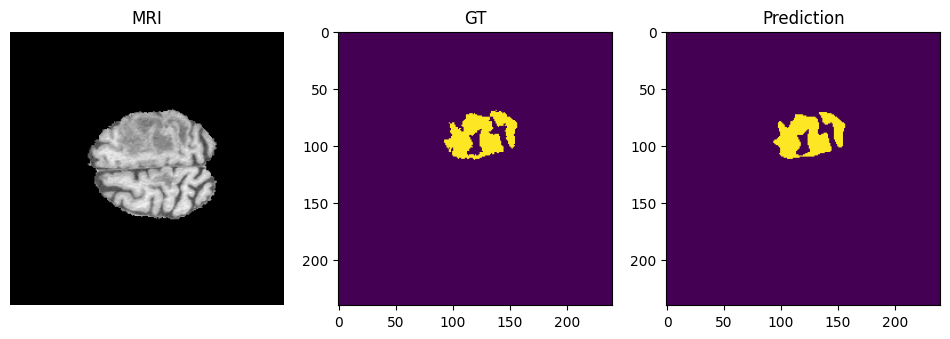

In [57]:
# ================================
# VISUALIZATION
# ================================

model.eval()

with torch.no_grad():
    images, masks = next(iter(val_loader))
    outputs = torch.sigmoid(model(images.to(device))).cpu()

idx = 0

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(images[idx][4], cmap='gray')  # center slice
plt.title("MRI")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(masks[idx][0])
plt.title("GT")

plt.subplot(1,3,3)
plt.imshow(outputs[idx][0] > 0.5)
plt.title("Prediction")

plt.show()

# Part 3 — 3D volumetric segmentation (aligned with 2.5D cohort)

Full 3D volumes (4 MRI modalities → binary tumor mask). **Re-run all Part 3 cells** from bootstrap through comparison.

Settings (matched to 2.5D for fair comparison):

- **100 patients** (same as 2.5D `num_patients = 100`)
- **128×128×128** full volumes; **96³ tumor-centered patches** during training
- **Patient-level** train/val split (`random_state=42`)
- **45 epochs**, patch sampling (4 crops/volume/epoch), best-checkpoint + threshold tuning
- **GPU required** (`REQUIRE_GPU_3D=True`): CUDA + mixed precision (AMP) + cuDNN benchmark

In [2]:
# ================================
# BOOTSTRAP (run this cell if you skip to Part 3 only)
# ================================
import os
import sys
from pathlib import Path

import importlib.util
import subprocess
import sys

def _ensure_packages(pip_names):
    missing = [p for p in pip_names if importlib.util.find_spec(p) is None]
    if missing:
        subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
        importlib.invalidate_caches()

_ensure_packages(["numpy", "matplotlib", "nibabel", "scikit-learn", "torch", "tqdm"])

import random
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

def resolve_brats2020_training_dir():
    env = os.environ.get("BRATS2020_TRAINING_DIR", "").strip()
    if env:
        p = Path(env)
        if p.is_dir():
            return str(p.resolve())
    root = Path.cwd().resolve()
    candidates = [
        root / "data" / "BraTS2020_TrainingData" / "MICCAI_BraTS2020_TrainingData",
        root / "data" / "MICCAI_BraTS2020_TrainingData",
        root / "BraTS2020_TrainingData" / "MICCAI_BraTS2020_TrainingData",
        root / "MICCAI_BraTS2020_TrainingData",
    ]
    for c in candidates:
        if c.is_dir():
            return str(c.resolve())
    raise FileNotFoundError("Could not find MICCAI_BraTS2020_TrainingData")

def setup_pytorch_device(require_gpu=False):
    """Select CUDA for 3D training; probe Conv3d kernels (needed for AttentionUNet3D)."""
    if not torch.cuda.is_available():
        if require_gpu:
            raise RuntimeError(
                "CUDA not available. Install GPU PyTorch in this kernel, e.g.:\n"
                "  %pip install torch torchvision --index-url https://download.pytorch.org/whl/cu124\n"
                "Then restart the kernel and re-run Part 3."
            )
        print("WARNING: CUDA not available — 3D training will be very slow on CPU.")
        return torch.device("cpu")
    try:
        # Conv3d probe (2D probe alone can pass while 3D kernels are missing)
        torch.nn.functional.conv3d(
            torch.zeros(1, 4, 8, 8, 8, device="cuda"),
            torch.zeros(4, 4, 3, 3, 3, device="cuda"),
            padding=1,
        )
        torch.backends.cudnn.benchmark = True  # faster fixed-size 3D convs
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        if hasattr(torch, "set_float32_matmul_precision"):
            torch.set_float32_matmul_precision("high")
        return torch.device("cuda")
    except RuntimeError as err:
        if require_gpu:
            raise RuntimeError(
                "CUDA is installed but Conv3d failed on GPU (wrong PyTorch/CUDA build?).\n"
                f"  {err}\n"
                "Try: pip install torch --index-url https://download.pytorch.org/whl/cu124"
            ) from err
        print("CUDA probe failed; falling back to CPU:", err)
        return torch.device("cpu")


device = setup_pytorch_device(require_gpu=False)
train_path = resolve_brats2020_training_dir()
patients = sorted(
    p for p in os.listdir(train_path)
    if os.path.isdir(os.path.join(train_path, p)) and p.startswith("BraTS")
)
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    props = torch.cuda.get_device_properties(0)
    print(f"VRAM: {props.total_memory / 1e9:.1f} GB | cuDNN benchmark: on | TF32: on")
print("Training data:", train_path)
print("Patients:", len(patients))

Using device: cuda
GPU: NVIDIA GeForce RTX 5070
VRAM: 12.8 GB | cuDNN benchmark: on | TF32: on
Training data: D:\MSAI\Semester 2\Deep Learning\Project\Project\AI600-DeepLearning2502-SemesterProject\data\BraTS2020_TrainingData\MICCAI_BraTS2020_TrainingData
Patients: 369


In [3]:
# ================================
# 3D CONFIG
# ================================

NUM_PATIENTS_3D = 100  # same cohort size as 2.5D
VOLUME_SIZE_3D = (128, 128, 128)  # (D, H, W) for Conv3d
MIN_TUMOR_VOXELS_3D = 100
BATCH_SIZE_3D = 1
NUM_EPOCHS_3D = 45
LR_3D = 1e-4
BASE_CHANNELS_3D = 32
PATCH_TRAIN_3D = True
PATCH_SIZE_3D = (96, 96, 96)
PATCHES_PER_VOLUME_3D = 4  # random tumor-centered crops per patient per epoch
VAL_SPLIT_3D = 0.2
SPLIT_SEED_3D = 42
REQUIRE_GPU_3D = True  # stop early if this notebook cell cannot use CUDA
# DataLoader workers: 0 on CPU; 2 on Windows+GPU, 4 on Linux+GPU (overlap load vs GPU)
NUM_WORKERS_3D = 0 if device.type != "cuda" else (2 if sys.platform == "win32" else 4)

if REQUIRE_GPU_3D and device.type != "cuda":
    device = setup_pytorch_device(require_gpu=True)

print(
    "3D setup:", NUM_PATIENTS_3D, "patients,",
    VOLUME_SIZE_3D, "full volume,",
    "patch", PATCH_SIZE_3D if PATCH_TRAIN_3D else "off,",
    "epochs", NUM_EPOCHS_3D,
    "| device:", device,
    "| AMP:", device.type == "cuda",
    "| workers:", NUM_WORKERS_3D,
)

3D setup: 100 patients, (128, 128, 128) full volume, patch (96, 96, 96) epochs 45 | device: cuda | AMP: True | workers: 2


In [4]:
# ================================
# LOAD + RESIZE 3D VOLUMES (100 patients)
# ================================

import torch.nn.functional as F

def load_patient_volume(patient_path):
    files = os.listdir(patient_path)
    t1 = nib.load(os.path.join(patient_path, [f for f in files if "t1.nii" in f.lower()][0])).get_fdata()
    t1ce = nib.load(os.path.join(patient_path, [f for f in files if "t1ce" in f.lower()][0])).get_fdata()
    t2 = nib.load(os.path.join(patient_path, [f for f in files if "t2.nii" in f.lower()][0])).get_fdata()
    flair = nib.load(os.path.join(patient_path, [f for f in files if "flair" in f.lower()][0])).get_fdata()
    seg = nib.load(os.path.join(patient_path, [f for f in files if "seg" in f.lower()][0])).get_fdata()
    # nibabel (H, W, D) -> store as (4, D, H, W) for Conv3d (N, C, D, H, W)
    image = np.stack([t1, t1ce, t2, flair], axis=0).astype(np.float32)
    image = np.transpose(image, (0, 3, 1, 2))
    mask = (seg > 0).astype(np.float32)
    mask = np.transpose(mask, (2, 0, 1))  # (D, H, W)
    return image, mask


def resize_volume_3d(image, mask, target_size=VOLUME_SIZE_3D):
    """image (4,D,H,W), mask (D,H,W) -> resized same layout."""
    img_t = torch.from_numpy(image).float().unsqueeze(0)  # (1, 4, D, H, W)
    msk_t = torch.from_numpy(mask).float().unsqueeze(0).unsqueeze(0)
    img_r = F.interpolate(img_t, size=target_size, mode="trilinear", align_corners=False)
    msk_r = F.interpolate(msk_t, size=target_size, mode="nearest")
    image = img_r.squeeze(0).numpy()
    mask = (msk_r.squeeze().numpy() > 0.5).astype(np.float32)
    return image, mask


from tqdm.auto import tqdm

volumes_3d = []
skipped_3d = []

print(f"Loading {NUM_PATIENTS_3D} patients (resize to {VOLUME_SIZE_3D}) — may take 10–20 min...", flush=True)
for patient in tqdm(patients[:NUM_PATIENTS_3D], desc="Load 3D volumes", unit="patient"):
    patient_path = os.path.join(train_path, patient)
    image, mask = load_patient_volume(patient_path)
    if mask.sum() < MIN_TUMOR_VOXELS_3D:
        skipped_3d.append((patient, "no tumor"))
        continue
    image, mask = resize_volume_3d(image, mask)
    if mask.sum() < 10:
        skipped_3d.append((patient, "tumor lost after resize"))
        continue
    volumes_3d.append({"patient": patient, "image": image, "mask": mask})

print("Loaded 3D volumes:", len(volumes_3d))
if skipped_3d:
    print("Skipped:", skipped_3d[:5], "..." if len(skipped_3d) > 5 else "")

Loading 100 patients (resize to (128, 128, 128)) — may take 10–20 min...


c:\Users\Osama\.pyenv\pyenv-win\versions\3.12.9\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Load 3D volumes:   0%|          | 0/100 [00:00<?, ?patient/s]

Load 3D volumes: 100%|██████████| 100/100 [00:57<00:00,  1.75patient/s]

Loaded 3D volumes: 100


In [5]:
# ================================
# PATIENT-LEVEL TRAIN / VAL SPLIT (3D)
# ================================

from sklearn.model_selection import train_test_split

train_volumes_3d, val_volumes_3d = train_test_split(
    volumes_3d, test_size=VAL_SPLIT_3D, random_state=SPLIT_SEED_3D
)

val_patient_ids_3d = [v["patient"] for v in val_volumes_3d]
train_patient_ids_3d = [v["patient"] for v in train_volumes_3d]

print("3D train patients:", len(train_volumes_3d))
print("3D val patients:", len(val_volumes_3d))
print("Val patient IDs (for fair 2.5D comparison):", val_patient_ids_3d[:3], "...")

3D train patients: 80
3D val patients: 20
Val patient IDs (for fair 2.5D comparison): ['BraTS20_Training_084', 'BraTS20_Training_054', 'BraTS20_Training_071'] ...


In [6]:
# ================================
# DATASET + DATALOADERS (3D)
# ================================

class BrainTumorVolumeDataset3D(Dataset):
    def __init__(self, volume_list, augment=False, patch_size=None, samples_per_volume=1):
        self.volume_list = volume_list
        self.augment = augment
        self.patch_size = patch_size
        self.samples_per_volume = max(1, int(samples_per_volume))

    def __len__(self):
        return len(self.volume_list) * self.samples_per_volume

    def _normalize(self, image):
        out = np.empty_like(image, dtype=np.float32)
        for c in range(image.shape[0]):
            ch = image[c]
            out[c] = (ch - ch.mean()) / (ch.std() + 1e-8)
        return out

    def _random_crop(self, image, mask):
        d, h, w = self.patch_size
        D, H, W = mask.shape
        if D <= d and H <= h and W <= w:
            return image, mask
        tumor_idx = np.argwhere(mask > 0)
        if len(tumor_idx) > 0 and random.random() < 0.7:
            cz, cy, cx = tumor_idx[random.randint(0, len(tumor_idx) - 1)]
        else:
            cz, cy, cx = D // 2, H // 2, W // 2
        z0 = int(np.clip(cz - d // 2, 0, max(0, D - d)))
        y0 = int(np.clip(cy - h // 2, 0, max(0, H - h)))
        x0 = int(np.clip(cx - w // 2, 0, max(0, W - w)))
        image = image[:, z0 : z0 + d, y0 : y0 + h, x0 : x0 + w]
        mask = mask[z0 : z0 + d, y0 : y0 + h, x0 : x0 + w]
        return image, mask

    def __getitem__(self, idx):
        item = self.volume_list[idx % len(self.volume_list)]
        image = item["image"].astype(np.float32)
        mask = (item["mask"] > 0).astype(np.float32)

        if self.patch_size is not None:
            image, mask = self._random_crop(image, mask)

        if self.augment:
            if random.random() < 0.5:
                image = image[:, ::-1].copy()
                mask = mask[::-1].copy()
            if random.random() < 0.5:
                image = image[:, :, ::-1].copy()
                mask = mask[:, ::-1].copy()
            image = image + np.random.randn(*image.shape).astype(np.float32) * 0.02

        image = self._normalize(image)
        image = torch.from_numpy(image)  # (4, D, H, W)
        mask = torch.from_numpy(mask).unsqueeze(0)  # (1, D, H, W)
        return image, mask


_patch_3d = PATCH_SIZE_3D if PATCH_TRAIN_3D else None
_samples_3d = PATCHES_PER_VOLUME_3D if PATCH_TRAIN_3D else 1
train_dataset_3d = BrainTumorVolumeDataset3D(
    train_volumes_3d,
    augment=True,
    patch_size=_patch_3d,
    samples_per_volume=_samples_3d,
)
val_dataset_3d = BrainTumorVolumeDataset3D(
    val_volumes_3d, augment=False, patch_size=None, samples_per_volume=1
)

_nw_3d = NUM_WORKERS_3D
_pin_3d = device.type == "cuda"
_dl_kw_3d = {"batch_size": BATCH_SIZE_3D, "pin_memory": _pin_3d}
if _nw_3d > 0:
    _dl_kw_3d.update(num_workers=_nw_3d, persistent_workers=True, prefetch_factor=2)

train_loader_3d = DataLoader(train_dataset_3d, shuffle=True, **_dl_kw_3d)
val_loader_3d = DataLoader(val_dataset_3d, shuffle=False, **_dl_kw_3d)

print(
    "3D DataLoader: batch", BATCH_SIZE_3D,
    "train steps/epoch", len(train_loader_3d),
    "val volumes", len(val_loader_3d),
    "num_workers", _nw_3d,
)

3D DataLoader: batch 1 train steps/epoch 320 val volumes 20 num_workers 2


In [7]:
# ================================
# 3D ATTENTION U-NET
# ================================

class DoubleConv3d(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)


class AttentionBlock3d(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Conv3d(F_g, F_int, 1)
        self.W_x = nn.Conv3d(F_l, F_int, 1)
        self.psi = nn.Conv3d(F_int, 1, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, g, x):
        psi = self.sigmoid(self.psi(torch.relu(self.W_g(g) + self.W_x(x))))
        return x * psi


class AttentionUNet3D(nn.Module):
    def __init__(self, in_channels=4, base=BASE_CHANNELS_3D):
        super().__init__()
        b = base

        self.down1 = DoubleConv3d(in_channels, b)
        self.pool1 = nn.MaxPool3d(2)

        self.down2 = DoubleConv3d(b, b * 2)
        self.pool2 = nn.MaxPool3d(2)

        self.down3 = DoubleConv3d(b * 2, b * 4)
        self.pool3 = nn.MaxPool3d(2)

        self.bottleneck = DoubleConv3d(b * 4, b * 8)

        self.up1 = nn.ConvTranspose3d(b * 8, b * 4, 2, stride=2)
        self.att1 = AttentionBlock3d(b * 4, b * 4, b * 2)
        self.conv1 = DoubleConv3d(b * 8, b * 4)

        self.up2 = nn.ConvTranspose3d(b * 4, b * 2, 2, stride=2)
        self.att2 = AttentionBlock3d(b * 2, b * 2, b)
        self.conv2 = DoubleConv3d(b * 4, b * 2)

        self.up3 = nn.ConvTranspose3d(b * 2, b, 2, stride=2)
        self.att3 = AttentionBlock3d(b, b, b // 2)
        self.conv3 = DoubleConv3d(b * 2, b)

        self.out = nn.Conv3d(b, 1, 1)

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(self.pool1(d1))
        d3 = self.down3(self.pool2(d2))

        bot = self.bottleneck(self.pool3(d3))

        u1 = self.up1(bot)
        d3 = self.att1(u1, d3)
        u1 = self.conv1(torch.cat([u1, d3], dim=1))

        u2 = self.up2(u1)
        d2 = self.att2(u2, d2)
        u2 = self.conv2(torch.cat([u2, d2], dim=1))

        u3 = self.up3(u2)
        d1 = self.att3(u3, d1)
        u3 = self.conv3(torch.cat([u3, d1], dim=1))

        return self.out(u3)

In [8]:
# ================================
# LOSS + OPTIMIZER (3D)
# ================================

class DiceLoss3D(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, preds, targets):
        preds = torch.sigmoid(preds).reshape(-1)
        targets = targets.reshape(-1)
        inter = (preds * targets).sum()
        dice = (2.0 * inter + self.smooth) / (preds.sum() + targets.sum() + self.smooth)
        return 1.0 - dice.clamp(0.0, 1.0)


# Class imbalance: foreground voxels are rare in full volumes
_fg = sum(v["mask"].sum() for v in train_volumes_3d)
_total = sum(v["mask"].size for v in train_volumes_3d)
_bg = max(_total - _fg, 1.0)
_pos_weight = torch.tensor([min(_bg / max(_fg, 1.0), 50.0)], device=device)
bce_3d = nn.BCEWithLogitsLoss(pos_weight=_pos_weight)
dice_loss_3d = DiceLoss3D()


def combined_loss_3d(preds, targets):
    return dice_loss_3d(preds, targets) + bce_3d(preds, targets)


def dice_score_3d(preds, targets, thresh=0.5):
    preds = (preds > thresh).float()
    intersection = (preds * targets).sum()
    return (2 * intersection / (preds.sum() + targets.sum() + 1e-6)).item()


model_3d = AttentionUNet3D().to(device)
optimizer_3d = torch.optim.Adam(model_3d.parameters(), lr=LR_3D)
scheduler_3d = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_3d, mode="min", factor=0.5, patience=3
)
best_val_dice_3d = 0.0
best_state_3d = None
print(f"3D BCE pos_weight: {_pos_weight.item():.1f} (fg voxels ~{_fg/_total*100:.3f}%)")

_use_cuda_amp_3d = device.type == "cuda"
try:
    from torch.amp import GradScaler, autocast

    scaler_3d = GradScaler("cuda", enabled=_use_cuda_amp_3d)

    def _autocast_3d():
        return autocast("cuda", enabled=_use_cuda_amp_3d)
except ImportError:
    from torch.cuda.amp import GradScaler, autocast

    scaler_3d = GradScaler(enabled=_use_cuda_amp_3d)

    def _autocast_3d():
        return autocast(enabled=_use_cuda_amp_3d)

print("3D model parameters:", sum(p.numel() for p in model_3d.parameters()) / 1e6, "M")
print("3D model device:", next(model_3d.parameters()).device)
print("Mixed precision (AMP):", "enabled" if _use_cuda_amp_3d else "disabled (CPU)")

3D BCE pos_weight: 50.0 (fg voxels ~0.867%)
3D model parameters: 5.626964 M
3D model device: cuda:0
Mixed precision (AMP): enabled


In [ ]:
# ================================
# TRAINING (3D) — saves best checkpoint by validation Dice
# Logs appear after EACH epoch (train ~320 steps + full-volume val). First line may take 10–30 min.
# ================================

import random
import time
from tqdm.auto import tqdm

_nb_3d = device.type == "cuda"
_log_every_3d = max(1, len(train_loader_3d) // 10)  # ~10 progress lines per epoch

print(
    f"Starting 3D training: {NUM_EPOCHS_3D} epochs, "
    f"{len(train_loader_3d)} train steps/epoch, "
    f"{len(val_loader_3d)} val volumes, device={device}",
    flush=True,
)


def _eval_val_dice_3d():
    model_3d.eval()
    scores = []
    with torch.inference_mode():
        for images, masks in val_loader_3d:
            images = images.to(device, non_blocking=_nb_3d)
            masks = masks.to(device, non_blocking=_nb_3d)
            if _use_cuda_amp_3d:
                with _autocast_3d():
                    outputs = torch.sigmoid(model_3d(images))
            else:
                outputs = torch.sigmoid(model_3d(images))
            for i in range(outputs.shape[0]):
                scores.append(dice_score_3d(outputs[i], masks[i]))
    return sum(scores) / max(len(scores), 1)


for epoch in range(NUM_EPOCHS_3D):
    t_epoch = time.time()
    model_3d.train()
    train_loss = 0.0

    train_bar = tqdm(
        train_loader_3d,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS_3D} train",
        leave=False,
        dynamic_ncols=True,
    )
    for step, (images, masks) in enumerate(train_bar, start=1):
        images = images.to(device, non_blocking=_nb_3d)
        masks = masks.to(device, non_blocking=_nb_3d)
        optimizer_3d.zero_grad(set_to_none=True)

        if _use_cuda_amp_3d:
            with _autocast_3d():
                outputs = model_3d(images)
                loss = combined_loss_3d(outputs, masks)
            scaler_3d.scale(loss).backward()
            scaler_3d.step(optimizer_3d)
            scaler_3d.update()
        else:
            outputs = model_3d(images)
            loss = combined_loss_3d(outputs, masks)
            loss.backward()
            optimizer_3d.step()

        train_loss += loss.item()
        if step % _log_every_3d == 0 or step == len(train_loader_3d):
            train_bar.set_postfix(loss=f"{loss.item():.4f}")

    model_3d.eval()
    val_loss = 0.0
    val_bar = tqdm(
        val_loader_3d,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS_3D} val",
        leave=False,
        dynamic_ncols=True,
    )
    with torch.inference_mode():
        for images, masks in val_bar:
            images = images.to(device, non_blocking=_nb_3d)
            masks = masks.to(device, non_blocking=_nb_3d)
            if _use_cuda_amp_3d:
                with _autocast_3d():
                    outputs = model_3d(images)
                    loss = combined_loss_3d(outputs, masks)
            else:
                outputs = model_3d(images)
                loss = combined_loss_3d(outputs, masks)
            val_loss += loss.item()

    val_loss_avg = val_loss / len(val_loader_3d)
    val_dice = _eval_val_dice_3d()
    scheduler_3d.step(val_loss_avg)

    if val_dice > best_val_dice_3d:
        best_val_dice_3d = val_dice
        best_state_3d = {k: v.detach().cpu().clone() for k, v in model_3d.state_dict().items()}

    elapsed = time.time() - t_epoch
    print(
        f"3D Epoch {epoch + 1}/{NUM_EPOCHS_3D}: "
        f"Train={train_loss / len(train_loader_3d):.4f}, "
        f"Val={val_loss_avg:.4f}, ValDice={val_dice:.4f}, "
        f"BestDice={best_val_dice_3d:.4f}, "
        f"time={elapsed / 60:.1f} min",
        flush=True,
    )

if best_state_3d is not None:
    model_3d.load_state_dict(best_state_3d)
    print("Loaded best 3D weights (val Dice =", f"{best_val_dice_3d:.4f})")

Starting 3D training: 45 epochs, 320 train steps/epoch, 20 val volumes, device=cuda


Epoch 1/45 train:   0%|          | 0/320 [00:00<?, ?it/s]

In [14]:
# ================================
# DICE SCORE (3D) — threshold tuning on val, then per-patient Dice
# ================================

THRESHOLDS_3D = [0.35, 0.4, 0.45, 0.5, 0.55, 0.6]
best_thresh_3d = 0.5
best_mean_at_thresh = -1.0

model_3d.eval()
val_probs_3d, val_masks_3d = [], []
_nb_eval = device.type == "cuda"

with torch.inference_mode():
    for images, masks in val_loader_3d:
        images = images.to(device, non_blocking=_nb_eval)
        if _use_cuda_amp_3d:
            with _autocast_3d():
                outputs = torch.sigmoid(model_3d(images)).cpu()
        else:
            outputs = torch.sigmoid(model_3d(images)).cpu()
        for i in range(outputs.shape[0]):
            val_probs_3d.append(outputs[i])
            val_masks_3d.append(masks[i])

for t in THRESHOLDS_3D:
    s = [dice_score_3d(p, m, thresh=t) for p, m in zip(val_probs_3d, val_masks_3d)]
    m = sum(s) / len(s)
    if m > best_mean_at_thresh:
        best_mean_at_thresh = m
        best_thresh_3d = t

scores_3d = [
    dice_score_3d(p, m, thresh=best_thresh_3d)
    for p, m in zip(val_probs_3d, val_masks_3d)
]
mean_dice = sum(scores_3d) / len(scores_3d)
print(f"Best val threshold: {best_thresh_3d} (mean Dice {best_mean_at_thresh:.4f})")
print("3D patient-level Dice (val cohort):", mean_dice)
print("Per-patient:", [round(s, 4) for s in scores_3d])

3D Dice (val patients, best checkpoint): 0.7157579123973846
Per-patient: [0.6864, 0.8509, 0.7566, 0.643, 0.468, 0.7673, 0.4847, 0.8576, 0.8085, 0.8348]


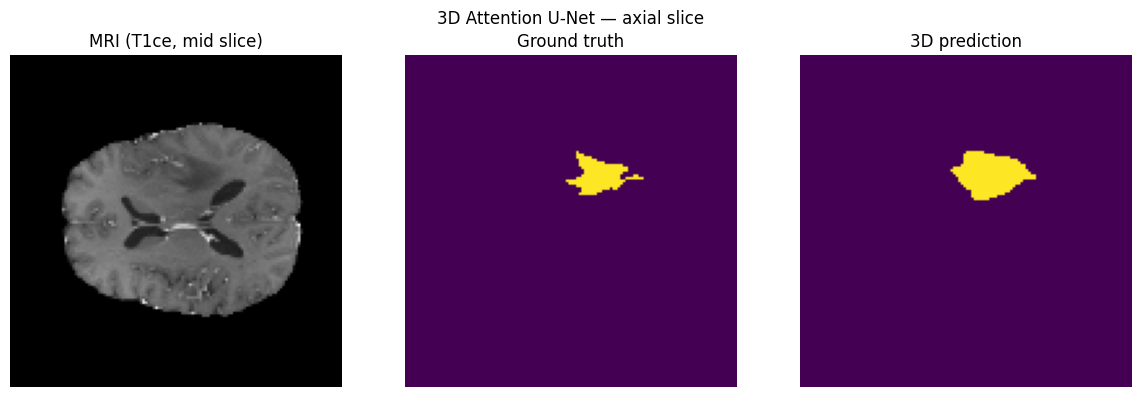

In [15]:
# ================================
# VISUALIZATION (3D — middle axial slice)
# ================================

model_3d.eval()

with torch.no_grad():
    images, masks = next(iter(val_loader_3d))
    outputs = torch.sigmoid(model_3d(images.to(device))).cpu()

idx = 0
slice_idx = images.shape[2] // 2  # D axis: (B, C, D, H, W)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(images[idx][1, slice_idx], cmap="gray")  # T1ce
plt.title("MRI (T1ce, mid slice)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(masks[idx][0, slice_idx])
plt.title("Ground truth")
plt.axis("off")

plt.subplot(1, 3, 3)
_viz_thresh = globals().get("best_thresh_3d", 0.5)
plt.imshow(outputs[idx][0, slice_idx] > _viz_thresh)
plt.title(f"3D prediction (t={_viz_thresh})")
plt.axis("off")

plt.suptitle("3D Attention U-Net — axial slice")
plt.tight_layout()
plt.show()

In [ ]:
# ================================
# FAIR COMPARISON: 2.5D vs 3D on the SAME val patients
# Run Part 2 (2.5D) first so `model` is trained. Re-run 3D eval cell for best_thresh_3d.
# ================================

def _dice_tensor(preds, targets, threshold=0.5):
    preds = (preds > threshold).float()
    inter = (preds * targets).sum()
    return (2 * inter / (preds.sum() + targets.sum() + 1e-6)).item()


def patient_dice_25d(patient_id, threshold=0.5):
    """Mean slice Dice on one patient (native resolution, same slices as training)."""
    patient_path = os.path.join(train_path, patient_id)
    files = os.listdir(patient_path)
    t1 = nib.load(os.path.join(patient_path, [f for f in files if "t1.nii" in f.lower()][0])).get_fdata()
    t1ce = nib.load(os.path.join(patient_path, [f for f in files if "t1ce" in f.lower()][0])).get_fdata()
    t2 = nib.load(os.path.join(patient_path, [f for f in files if "t2.nii" in f.lower()][0])).get_fdata()
    flair = nib.load(os.path.join(patient_path, [f for f in files if "flair" in f.lower()][0])).get_fdata()
    seg = nib.load(os.path.join(patient_path, [f for f in files if "seg" in f.lower()][0])).get_fdata()
    image = np.stack([t1, t1ce, t2, flair], axis=0)
    slices = create_slices_25d(image, seg)
    if not slices:
        return float("nan")
    dices = []
    model.eval()
    with torch.no_grad():
        for img, msk in slices:
            x = torch.from_numpy(img).float().unsqueeze(0).to(device)
            y = torch.from_numpy(msk).float().unsqueeze(0).unsqueeze(0).to(device)
            out = torch.sigmoid(model(x))
            dices.append(_dice_tensor(out[0], y[0], threshold=threshold))
    return float(np.mean(dices))


if "model" not in globals():
    raise RuntimeError("Train/load the 2.5D `model` (Part 2) before running this cell.")

_thresh_3d = globals().get("best_thresh_3d", 0.5)
scores_25d_fair = []
scores_3d_fair = list(globals().get("scores_3d", []))

if len(scores_3d_fair) != len(val_patient_ids_3d):
    scores_3d_fair = []
    model_3d.eval()
    with torch.no_grad():
        for images, masks in val_loader_3d:
            images = images.to(device)
            outputs = torch.sigmoid(model_3d(images)).cpu()
            for i in range(outputs.shape[0]):
                scores_3d_fair.append(
                    dice_score_3d(outputs[i], masks[i], thresh=_thresh_3d)
                )

for pid in val_patient_ids_3d:
    scores_25d_fair.append(patient_dice_25d(pid))

mean_25d = float(np.nanmean(scores_25d_fair))
mean_3d = float(np.mean(scores_3d_fair))

print("=" * 60)
print("Fair comparison (same", len(val_patient_ids_3d), "val patients, patient-level Dice)")
print("  2.5D (slice-mean per patient):", round(mean_25d, 4))
print(f"  3D   (full volume, t={_thresh_3d}):", round(mean_3d, 4))
print("=" * 60)
for i, pid in enumerate(val_patient_ids_3d):
    print(f"  {pid}: 2.5D={scores_25d_fair[i]:.4f}  3D={scores_3d_fair[i]:.4f}")
print("Train patients:", len(train_patient_ids_3d), "| Val patients:", len(val_patient_ids_3d))